# A/B Testing Review

A/B testing is the simplest form of a randomized controlled experiment used to compare two versions of something to figure out which performs better. 
In the 1920s, Ronald Fisher firstly figured out the basic principles, statistics, and mathematics behind A/B testing by designing what effect various external factors had on the growth of plants, and established the principles of the modern hypothesis testing experiments. These principles were adopted by clinical trials in medicine in the early 1950s, then applied by marketers to evaluate direct response campaigns in the 1960s and 1970s. In the last decades, A/B testing was used by businesses of all sizes across various industries, from website design to online offers to headlines to product descriptions. 
 
The following figure shows how to use different statistical methods to make A/B testing successful based on the metrics, sample size, and sampling distributions of your data.

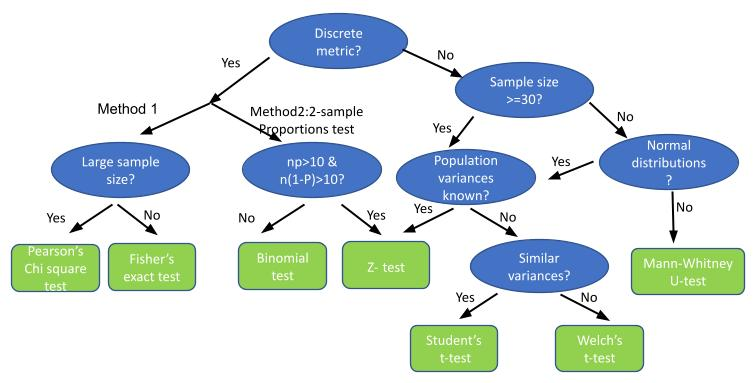

**Discrete metrics VS.continuous metrics**

**1. Discrete metrics**，also called binomial metrics, have only two values 0 and 1, such as ***click-through rate, conversion rate, bounce rate***.

**2. continuous metrics,** also called non-binomial metrics, can take continuous values that are not limited to 0 and 1, such as ***average revenue, average session duration for a custormer stay on a website,  average order value for the custormers***.

**One-tailed test VS. two-tailed test**

The choice of one-tailed test or two-tailed test depends on the original claim in the question. A one-tailed test looks for an “increase” or “decrease” (>,<are used in H1), whereas a two-tailed test looks for a “change”(≠is used in H1). When is a one tailed test appropriate?

The one-tailed test provides more power to detect an effect, but must be very careful about the consequences of missing an effect in the other direction.  Imagine you have developed a new drug that you believe is an improvement over an existing drug.  You wish to maximize your ability to detect the improvement, so you opt for a one-tailed test. In doing so, you fail to test for the possibility that the new drug is less effective than the existing drug. 

If you have considered the consequences of missing an effect in the untested direction, and conclude that they are negligible, You can proceed with a one-tailed test. In scenario two, you produce a new drug, and the cost is much lower than the old one. You are only interested if it is less effective than the old drug. If not, the new drug will be successful. You do not need to care if it is significantly more effective. Then, A one-tailed test would be appropriate for another directional effect is negligible.

When doing A/B testing, there are also several mistakes to be easily made: making a decision too quickly without letting the test run its entire course,  or not doing enough retesting, those two might cause Type 1/2 error; and looking at too many metrics instead of focusing on the ones they most care about, which might cause decision confusion. (See mobile games the example: we can do A/B testing on sum_gamerounds, retention_1, retention_7)

[A/B Testing: A Complete Guide to Statistical Testing](https://towardsdatascience.com/a-b-testing-a-complete-guide-to-statistical-testing-e3f1db140499)

[A Refresher on A/B Testing](https://hbr.org/2017/06/a-refresher-on-abtesting#:~:text=A%2FB%20testing%20is%20a,decisions%20unless%20they%20have%20evidence.)

[FAQ: WHAT ARE THE DIFFERENCES BETWEEN ONE-TAILED AND TWO-TAILED TESTS?](https://stats.oarc.ucla.edu/other/mult-pkg/faq/general/faq-what-are-the-differences-between-one-tailed-and-two-tailed-tests/)




**1. E-commerce web designer (A/B testing on Discrete metrics: conversion rate)**

**2. More complex examples**
 
* **2. 1.  One-Way ANOVA test for one factor and mutiple groups**

* **2. 2.  Post-hoc tests for multiple pairwise comparisons** 

* **2. 3.  Two-Way ANOVA test for analyzing the mean responses in an experiment with two factors**

**3. Mobile Games examples**

* **3. 1. EDA**

* **3. 2. Detect and Remove Outerliers**

* **3. 3. A/B Testing on a continous metric: sum_gamerounds**

* **3. 4. A/B Testing on discrete metric: retention_1,retention_7**

In [1]:
import pandas as pd
import numpy as np
from numpy import percentile

import matplotlib.pyplot as plt
from pylab import rcParams
rcParams['figure.figsize'] = 15, 5
import seaborn as sns
sns.set_style("whitegrid")

import warnings
warnings.filterwarnings('ignore')

import scipy.stats as stats
from scipy.stats import shapiro

from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.graphics.factorplots import interaction_plot

**1. E-commerce web designer (A/B testing on Discrete metrics: conversion rate)**

In [2]:
df = pd.read_csv("../input/ecommerce-ab-testing-2022-dataset1/ecommerce_ab_testing_2022_dataset1/ab_data.csv")
df.head()

,user_id,timestamp,group,landing_page,converted
0,851104,11:48.6,control,old_page,0
1,804228,01:45.2,control,old_page,0
2,661590,55:06.2,treatment,new_page,0
3,853541,28:03.1,treatment,new_page,0
4,864975,52:26.2,control,old_page,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 294480 entries, 0 to 294479
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   user_id       294480 non-null  int64 
 1   timestamp     294480 non-null  object
 2   group         294480 non-null  object
 3   landing_page  294480 non-null  object
 4   converted     294480 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 11.2+ MB


In [4]:
# Data Cleaning
# Locate rows of duplicate data
dups = df.duplicated()
print(dups.any())

False


In [5]:
# Check duplicate user_id
df[df["user_id"].duplicated()]

,user_id,timestamp,group,landing_page,converted
2656,698120,13:42.6,control,old_page,0
2893,773192,55:59.6,treatment,new_page,0
7500,899953,06:54.1,control,new_page,0
8036,790934,32:20.3,treatment,new_page,0
10218,633793,16:00.7,treatment,old_page,0
...,...,...,...,...,...
294309,787083,15:21.0,control,old_page,0
294328,641570,59:27.7,control,old_page,0
294331,689637,34:28.3,control,new_page,0
294355,744456,32:07.1,treatment,new_page,0


In [6]:
df[df["user_id"]==698120]

,user_id,timestamp,group,landing_page,converted
988,698120,09:37.5,control,new_page,0
2656,698120,13:42.6,control,old_page,0


In [7]:
# Check if there is mismatch between group and landing_page
df_mismatch = df[(df["group"]=="treatment")&(df["landing_page"]=="old_page")
                |(df["group"]=="control")&(df["landing_page"]=="new_page")]
n_mismatch = df_mismatch.shape[0]
print(f"The number of mismatched rows:{n_mismatch} rows" )
print("Percent of mismatched rows:%.2f%%" % (n_mismatch/df.shape[0]*100))

The number of mismatched rows:3893 rows
Percent of mismatched rows:1.32%


 As you can see, there are 3893 rows mismatched, which means that treatment group mismatched with old_page and control group mismatched with new_page.There are also 3895 duplicated user_id, some of them loading both new page and old page. This might be the relative department repeat the expermient after finding the mismatched problem. Therefore, we need to only keep the right data and drop the mismatched data.   

In [8]:
df2 = df[(df["group"]=="treatment")&(df["landing_page"]=="new_page")
                |(df["group"]=="control")&(df["landing_page"]=="old_page")]

In [9]:
# Check duplicate user_id again
df2[df2["user_id"].duplicated()]


,user_id,timestamp,group,landing_page,converted
2893,773192,55:59.6,treatment,new_page,0
294478,759899,20:29.0,treatment,new_page,0


In [10]:
df2[df2["user_id"]==773192]

,user_id,timestamp,group,landing_page,converted
1899,773192,37:58.8,treatment,new_page,0
2893,773192,55:59.6,treatment,new_page,0


In [11]:
df2.drop_duplicates(subset="user_id",inplace=True) 

In [12]:
df2.shape

(290585, 5)

In [13]:
# Conversion Rate
df_counts = pd.DataFrame({"Control_COUNT": df2[df2.group=="control"].converted.value_counts(),
              "Treatment_COUNT": df2[df2.group=="treatment"].converted.value_counts(),
              "Control_RATIO": df2[df2.group=="control"].converted.value_counts()/ len(df2[df2.group=="control"]),
              "Trement_RATIO": df2[df2.group=="treatment"].converted.value_counts() / len(df2[df2.group=="treatment"])})
df_counts

,Control_COUNT,Treatment_COUNT,Control_RATIO,Trement_RATIO
0,127785,128047,0.879614,0.881193
1,17489,17264,0.120386,0.118807


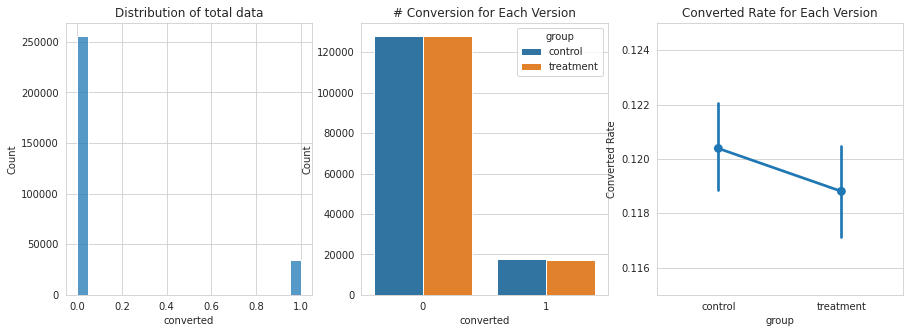

In [14]:
fig, axes = plt.subplots(1,3)

sns.histplot(x="converted", data=df2, ax=axes[0])
axes[0].set_title("Distribution of total data")

sns.countplot(x="converted", data=df2, hue="group", ax=axes[1])
axes[1].set(title="# Conversion for Each Version", ylabel="Count")

sns.pointplot(x="group", y="converted",kind="point", data=df2, ax=axes[2])
axes[2].set_ylim([0.115, 0.125])
axes[2].set(title="Converted Rate for Each Version",ylabel="Converted Rate")

plt.show()

As you can see from the above figures:

1. The Conversion number is a discrete metric, with only 0 or 1 value, the sample size of the data is large, so Pearson's chi-square test is much better to be applied.

2. The conversion rate of the new version is slightly lower than that of the old version, but there is some overlap between the two versions, so the difference doesn't look significant.  

H0: conversion rate of Control verson = conversion rate of treatmentment

H1: conversion rate of Control verson != conversion rate of treatmentment

In [15]:
table = df_counts.iloc[:,0:2].to_numpy()
table

array([[127785, 128047],
       [ 17489,  17264]])

In [16]:
# chi-squared test 
stat, p, dof, expected = stats.chi2_contingency(table)
print("fredoom of degree=%d"% dof)
print(expected)
# interpret test-statistic
prob = 0.95
critical = stats.chi2.ppf(prob, dof)
print('probability=%.3f, critical=%.3f, stat=%.3f' % (prob, critical, stat))
if abs(stat) >= critical:
    print('Dependent (reject H0)')
else:
    print('Independent (fail to reject H0)')
# interpret p-value
alpha = 1-prob
print('significance=%.3f, p=%.3f' % (alpha, p))
if p <= alpha:
    print('Dependent (reject H0)')
else:
    print('Independent (fail to reject H0)')

fredoom of degree=1
[[127899.7125385 127932.2874615]
 [ 17374.2874615  17378.7125385]]
probability=0.950, critical=3.841, stat=1.705
Independent (fail to reject H0)
significance=0.050, p=0.192
Independent (fail to reject H0)


In [17]:
# Fishers exact test on the data
odd_ratio, p_value = stats.fisher_exact(table, alternative="two-sided")
print("odd ratio is : " + str(odd_ratio))
print("p_value is : " + str(p_value))
if p_value <= alpha:
    print('Dependent (reject H0)')
else:
    print('Independent (fail to reject H0)')

odd ratio is : 0.9851149705891606
p_value is : 0.19047607138920358
Independent (fail to reject H0)


In [18]:
# A/B Testing on discrete metrics-------solution
def AB_testing(dataframe, group, metric):
    
    # Split groups
    group_c = dataframe[dataframe[group] == "control"][metric]
    group_t = dataframe[dataframe[group] == "treatment"][metric]
    
    size = dataframe.shape[0]  
    table = pd.DataFrame({"C_COUNT": group_c.value_counts(),
              "T_COUNT": group_t.value_counts()}).to_numpy()
    
    if size < 1000:
        # Fisher Exact Test
        odd_ratio, p_value = stats.fisher_exact(table, alternative="two-sided")
    else:
        # Pearson Chi Square Test
        stat, p_value, dof, expected = stats.chi2_contingency(table)
    # Result
    temp = pd.DataFrame({
        "Test":[size<1000],
        "P_value":[p_value],
        "AB Hypothesis":[p_value < 0.05], 
    })
    temp["Test"] = np.where(temp["Test"]==True, "Fisher Exact Test", "Chi Square Test")
    temp["AB Hypothesis"] = np.where(temp["AB Hypothesis"] == False, "Fail to Reject H0", "Reject H0")
    temp["Comment"] = np.where(temp["AB Hypothesis"] == "Fail to Reject H0", "A/B groups are similar!", "A/B groups are not similar!")
    
    return temp
   
# Apply A/B Testing
AB_testing(dataframe=df2, group = "group", metric = "converted")

,Test,P_value,AB Hypothesis,Comment
0,Chi Square Test,0.19159,Fail to Reject H0,A/B groups are similar!


**2. More complex examples**
 
In the real word problem, we should run more complex tests, like mutigroups pairwise tests, mutifactors tests.

* **2. 1.  One-Way ANOVA test for one factor and mutiple groups testing**

If the overall p-value from the ANOVA table is less than some significance level, then we have sufficient evidence to say that at least one of the means of the groups is different from the others.This method doesn’t tell us which groups are different from each other. We must conduct a post hoc test.

In [19]:
# Create a fake 3-groups dada 
df_group3 = pd.DataFrame({"score": [87, 86, 88, 75, 78, 94, 98, 79, 71, 69,
                             91, 92, 90, 90, 97, 94, 82, 88, 95, 96,
                             88, 78, 88, 94, 93, 85, 83, 85, 82, 81],
                   "group": np.repeat(["A", "B", "C"], repeats=10)}) 
A = df_group3[df_group3["group"]=="A"].score
B = df_group3[df_group3["group"]=="B"].score
C = df_group3[df_group3["group"]=="C"].score

In [20]:
# Perform one-way ANOVA
stats.f_oneway(A, B, C)

F_onewayResult(statistic=4.491727279993608, pvalue=0.020702475181623638)

Since p-value from the ANOVA table is 0.02, less than .05, we have sufficient evidence to say that the mean values across each group are not equal.

* **2. 2.  Post-hoc tests for multiple pairwise comparisons** 

There are three testing methods: Bonferroni, Tukey's HSD, and Scheffe's test.  The bonferroni critical value is equal to p divided by the number of test. Bonferroni has more power when the number of comparisons is small, whereas Tukey is more powerful when testing large numbers of means.

[Tukey vs. Bonferroni vs. Scheffe: Which Test Should You Use?](https://www.statology.org/tukey-vs-bonferroni-vs-scheffe/)

In [21]:
# perform Tukey's test
tukey = pairwise_tukeyhsd(endog=df_group3['score'],
                          groups=df_group3['group'],
                          alpha=0.05)

#display results
print(tukey)

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     A      B      9.0  0.017   1.4521 16.5479   True
     A      C      3.2 0.5519  -4.3479 10.7479  False
     B      C     -5.8 0.1566 -13.3479  1.7479  False
-----------------------------------------------------


We would conclude that there is a statistically significant difference between the means of groups a and b, but not a statistically significant difference between the means of groups a and c, and groups b and c.

* **2. 3. Two-Way ANOVA test for analyzing the mean responses in an experiment with two factors**

[Three ways to do a two-way ANOVA with Python](https://www.marsja.se/three-ways-to-carry-out-2-way-anova-with-python/)

In [22]:
#Merge the countries data with df2
countries = pd.read_csv("../input/ecommerce-ab-testing-2022-dataset1/ecommerce_ab_testing_2022_dataset1/countries.csv")
countries.head()

,user_id,country
0,834778,UK
1,928468,US
2,822059,UK
3,711597,UK
4,710616,UK


In [23]:
df3 = df2.merge(countries, on="user_id",how="left")
df3.head()

,user_id,timestamp,group,landing_page,converted,country
0,851104,11:48.6,control,old_page,0,US
1,804228,01:45.2,control,old_page,0,US
2,661590,55:06.2,treatment,new_page,0,US
3,853541,28:03.1,treatment,new_page,0,US
4,864975,52:26.2,control,old_page,1,US


In [24]:
df3.isna().sum()

user_id         0
timestamp       0
group           0
landing_page    0
converted       0
country         0
dtype: int64

In [25]:
df3.country.value_counts()

US    203621
UK     72466
CA     14499
Name: country, dtype: int64

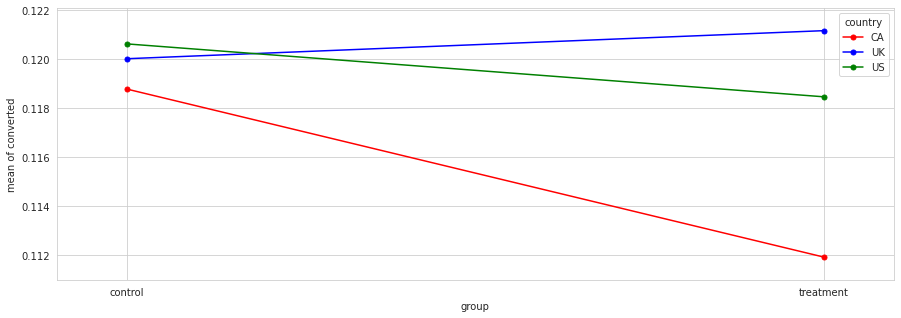

In [26]:
fig = interaction_plot(x=df3.group, trace=df3.country, response=df3.converted, colors=['red','blue','green'], ms=10)

In [27]:
pip install pingouin

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.4/185.4 kB 4.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... - done
  Preparing metadata (setup.py) ... - done
  Created wheel for pingouin: filename=pingouin-0.5.2-py3-none-any.whl size=196206 sha256=861daf9137dc9492270e5574ffcb214417d737d7f8dfc9903ceedfb5f873c50c
  Stored in directory: /root/.cache/pip/wheels/11/5a/63/a6d32fc26fa462c731f65480bfb98ff7bd39b8ebcb4bc6c2fe
  Created wheel for littleutils: filename=littleutils-0.2.2-py3-none-any.whl size=7048 sha256=9c3b11acebd6f884b731dede4fd01f8e289e6c171ab0e33989174607ef184852
  Stored in directory: /root/.cache/pip/wheels/d6/64/cd/32819b511a488e4993f2fab909a95330289c3f4e0f6ef4676d
Successfully built pingouin littleutils
Note: you may need to restart the kernel to use updated packages.


In [28]:
import pingouin as pg
aov = pg.anova(dv="converted", between=["group","country"], data=df3, detailed=True)
print(aov)

            Source            SS        DF        MS         F     p-unc  \
0            group      0.180217       1.0  0.180217  1.711582  0.190781   
1          country      0.336968       2.0  0.168484  1.600150  0.201868   
2  group * country      0.254275       2.0  0.127137  1.207469  0.298955   
3         Residual  30595.898465  290580.0  0.105293       NaN       NaN   

        np2  
0  0.000006  
1  0.000011  
2  0.000008  
3       NaN  


**3. A/B testing on Mobile Games**

Data Description from Aurelia Sui's notebook

The data is from 90,189 players that installed the game while the AB-test was running. The variables are:

userid - a unique number that identifies each player.

version - whether the player was put in the control group (gate_30 - a gate at level 30) or the test group (gate_40 - a gate at level 40).

sum_gamerounds - the number of game rounds played by the player during the first week after installation

retention_1 - did the player come back and play 1 day after installing?

retention_7 - did the player come back and play 7 days after installing?

When a player installed the game, he or she was randomly assigned to either gate_30 or gate_40.

* **3. 1.  EDA**

In [29]:
df_mg = pd.read_csv("../input/mobile-games-ab-testing/cookie_cats.csv")
df_mg.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [30]:
df_mg.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB


In [31]:
# Check duplicated row & userid
print(df_mg.duplicated().any())
print(df_mg["userid"].duplicated().any())

False
False


In [32]:
# goupby version & summary stats
df_mg.groupby("version").sum_gamerounds.agg(["count","min","max","mean","median","std"])

,count,min,max,mean,median,std
version,,,,,,
gate_30,44700,0,49854,52.456264,17.0,256.716423
gate_40,45489,0,2640,51.298776,16.0,103.294416


In [33]:
# Summary sum_gamerounds stats
df_30 = df_mg[df_mg.version == "gate_30"]
df_40 = df_mg[df_mg.version == "gate_40"]
stat_total = df_mg[["sum_gamerounds"]].describe([0.01, 0.05, 0.10, 0.25, 0.75, 0.90, 0.95, 0.99]).T
stat_30 = df_30[["sum_gamerounds"]].describe([0.01, 0.05, 0.10, 0.25, 0.75, 0.90, 0.95, 0.99]).T
stat_40 = df_40[["sum_gamerounds"]].describe([0.01, 0.05, 0.10, 0.25, 0.75, 0.90, 0.95, 0.99]).T
summary_stat = pd.concat([stat_total,stat_30,stat_40],keys=["stat_total", "stat_30", "stat_40"])

In [34]:
summary_stat

,,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
stat_total,sum_gamerounds,90189.0,51.872457,195.050858,0.0,0.0,1.0,1.0,5.0,16.0,51.0,134.0,221.0,493.00,49854.0
stat_30,sum_gamerounds,44700.0,52.456264,256.716423,0.0,0.0,1.0,1.0,5.0,17.0,50.0,135.0,222.0,493.00,49854.0
stat_40,sum_gamerounds,45489.0,51.298776,103.294416,0.0,0.0,1.0,1.0,5.0,16.0,52.0,134.0,220.0,492.12,2640.0


<AxesSubplot:xlabel='index'>

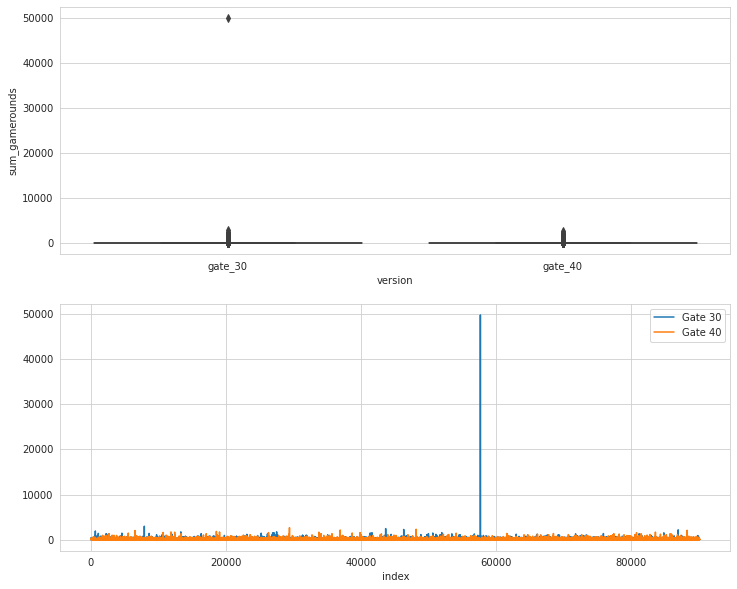

In [35]:
fig, axes = plt.subplots(2,figsize=(12,10))
sns.boxplot(x=df_mg.version, y=df_mg.sum_gamerounds, ax=axes[0])

df_30.reset_index().set_index("index").sum_gamerounds.plot(legend = True, label = "Gate 30",ax=axes[1])
df_40.reset_index().set_index("index").sum_gamerounds.plot(legend = True, label = "Gate 40",ax=axes[1])


* **3. 2. Detect and Remove Outerliers**

1. Standard Deviation Method: used for Gaussian or Gaussian-like data. Onew Standard Deviation from the Mean will cover 68 percent, two Standard Deviations from the Mean will cover 95 percent, and three Standard Deviations from the Mean will cover 99.7 percent.Three standard deviations from the mean is a common cut-off in practice for identifying outliers in a Gaussian or Gaussian-like distribution. For smaller samples of data, perhaps a value of 2 standard deviations (95 percent) can be used, and for larger samples, perhaps a value of 4 standard deviations (99.9 percent) can be used.

2. Interquartile Range Method (IQR): used for a non-Gaussian distribution. The IQR can then be calculated as the difference between the 75th and 25th percentiles. A factor k of the IQR below the 25th percentile or above the 75th percentilebe is used to identify outliers. The common valuefor the factor k is the value 1.5. A factor k of 3 or more can be used to identify values that are extreme outliers.

In [36]:
def outlier_detected(data):
    q25, q75 = percentile(data.sum_gamerounds, 25), percentile(data.sum_gamerounds, 75)
    iqr = q75 - q25
    # calculate the outlier cutoff
    cut_off = iqr * 4
    lower, upper = q25 - cut_off, q75 + cut_off
    print( "25th=%d, 75th=%d, IQR=%d, Lower=%d, Upper=%d" % (q25, q75, iqr, lower, upper))
    # identify outliers
    outliers = data[(data.sum_gamerounds <lower)|(data.sum_gamerounds >upper)]
    print( "The number of Identified outliers: %d" % len(outliers))
    outliers_removed = data[(data.sum_gamerounds >=lower) & (data.sum_gamerounds <=upper)]
    print("Percent of outliers: %.2f%%" % (100*(1-len(outliers_removed)/len(data))))
    return outliers_removed

df_c30 =  outlier_detected(df_30)   

25th=5, 75th=50, IQR=45, Lower=-175, Upper=230
The number of Identified outliers: 2085
Percent of outliers: 4.66%


In [37]:
df_c40 =  outlier_detected(df_40) 

25th=5, 75th=52, IQR=47, Lower=-183, Upper=240
The number of Identified outliers: 1963
Percent of outliers: 4.32%


In [38]:
df_clean = outlier_detected(df_mg) 

25th=5, 75th=51, IQR=46, Lower=-179, Upper=235
The number of Identified outliers: 4073
Percent of outliers: 4.52%


In this case, IQR method is not very well. Whether we directly remove outliers from the total data, or respectively remove outlier from two versions, the percentages of the removed outliers from the two versions will be different since the spreads and centers of their sum_gameground are not the same.  This might affect the testing result.

Let's do more analysis on some details. From the statistic summary, we notice that the distribution of the sum_gamerounds data is exponential-like, which centers in a small range with a long right tail.  About 50 percent of the total sum_gamerounds is the values between 5 and around 50.  As the values of the sum_gamerounds increase, the counts of the sum_gramerounds decrease dramatically. The values of the last 5 percent and 1 percent of the data are respectively larger than 220 and 492. How to choose the cutoff of the outliers might affect our test result. Therefore, it is better for us to list all of the testing results with the relevant outlier percentage. Then, the product development or other relevant development can make a decision depending on their concern. 

In [39]:
def outlier_removed(data1,data2,x):
    dc_1 = data1[data1.sum_gamerounds <=data1.sum_gamerounds.quantile(x)]
    dc_2 = data2[data2.sum_gamerounds <=data2.sum_gamerounds.quantile(x)]
    dc = pd.concat([dc_1,dc_2])
    print("Percent of outliers: %.2f%%" % (100*(1-len(dc)/len(df_mg))))
    return dc

data_clean =  outlier_removed(df_30,df_40, 0.95)

Percent of outliers: 4.98%


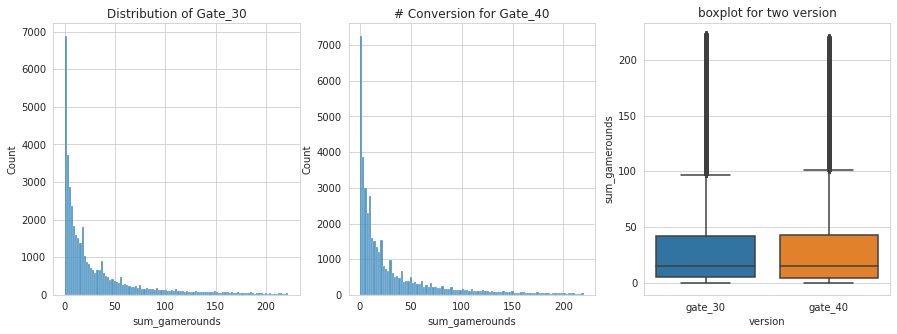

In [40]:
fig, axes = plt.subplots(1,3)

sns.histplot(x="sum_gamerounds", data=data_clean[data_clean.version=="gate_30"], ax=axes[0])
axes[0].set_title("Distribution of Gate_30")

sns.histplot(x="sum_gamerounds", data=data_clean[data_clean.version=="gate_40"],ax=axes[1])
axes[1].set(title="# Conversion for Gate_40")

sns.boxplot(x=data_clean.version, y=data_clean.sum_gamerounds, ax=axes[2])
axes[2].set(title="boxplot for two version")

plt.show()

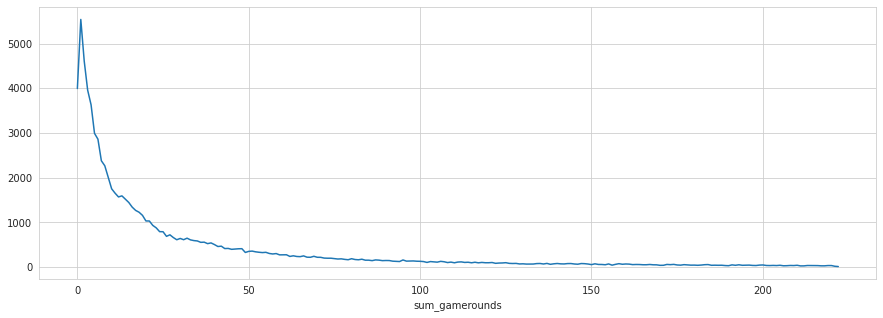

In [41]:
data_clean.groupby("sum_gamerounds").userid.count().plot()
plt.show()

In [42]:
counts = data_clean.groupby("sum_gamerounds").userid.count().reset_index()
counts[counts["userid"]==counts.userid.max()]

,sum_gamerounds,userid
1,1,5538


In [43]:
# Summary sum_gamerounds stats
df_clean_30 = data_clean[data_clean.version == "gate_30"]
df_clean_40 = data_clean[data_clean.version == "gate_40"]
stat_clean_total = data_clean[["sum_gamerounds"]].describe([0.01, 0.05, 0.10, 0.25, 0.75, 0.90, 0.95, 0.99]).T
stat_clean_30 = df_clean_30[["sum_gamerounds"]].describe([0.01, 0.05, 0.10, 0.25, 0.75, 0.90, 0.95, 0.99]).T
stat_clean_40 = df_clean_40[["sum_gamerounds"]].describe([0.01, 0.05, 0.10, 0.25, 0.75, 0.90, 0.95, 0.99]).T
summary_clean_stat = pd.concat([stat_clean_total,stat_clean_30,stat_clean_40],keys=["stat_clean_total", "stat_clean_30", "stat_clean_40"])
summary_clean_stat

,,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
stat_clean_total,sum_gamerounds,85702.0,33.162225,44.095410,0.0,0.0,1.0,1.0,4.0,15.0,43.0,96.0,138.0,198.0,222.0
stat_clean_30,sum_gamerounds,42477.0,33.233821,44.134720,0.0,0.0,1.0,1.0,5.0,15.0,42.0,95.0,138.0,199.0,222.0
stat_clean_40,sum_gamerounds,43225.0,33.091868,44.057144,0.0,0.0,1.0,1.0,4.0,15.0,43.0,96.0,137.0,197.0,220.0


* **3. 3. A/B Testing on a continous metric: sum_gamerounds**

As shown in the graph at the beginning of this notebook,  we need to do two tests first to make A/B testing successful.

* Using the Shapiro-Wilk test to check if each group was drawn from a normal distribution.

* If Normal distribution, Using Levene's test to check if k samples have equal variances (Homogeneity of variances).

* If Normal & homogeneity, apply T-test. 

* If Normal but non-homogeneity, apply Welch Test

* If Non-Normal, apply Mann Whitney U Test.

In [44]:
def AB_Test(dataframe, group, metric):

    # Split A/B
    groupA = dataframe[dataframe[group] == "gate_30"][metric]
    groupB = dataframe[dataframe[group] == "gate_40"][metric]
    
    # The Shapiro-Wilk test: Normality
    # H0: Distribution is Normal! - p_value > 0.05  
    # H1: Distribution is not Normal! - P_value < 0.05
    ntA = shapiro(groupA)[1] < 0.05
    ntB = shapiro(groupB)[1] < 0.05
    
    if (ntA == False) & (ntB == False): # The P values of both tests are great than 0.05, and both the two groups are drawing from Normal Distributions
        # Normal distribution
        # The levene test: Equality of variances
        # H0: Homogeneity: - p_value > 0.05 
        # H1: Heterogeneous: - P_value < 0.05
        leveneTest = stats.levene(groupA, groupB)[1] < 0.05

        
        if leveneTest == False: # The P-value of the test is greater than 0.05
            # Homogeneity
            # t-test: Equality of variances
            # H0: MA == MB 
            # H1: MA != MB 
            ttest = stats.ttest_ind(groupA, groupB, equal_var=True)[1]

        else:
            # Heterogeneous
            # H0: MA == MB 
            # H1: MA != MB 
            ttest = stats.ttest_ind(groupA, groupB, equal_var=False)[1]

    else:
        # Non-Normal
        # H0: MA == MB 
        # H1: MA != MB 
        ttest = stats.mannwhitneyu(groupA, groupB)[1] 

        
    # Result
    temp = pd.DataFrame({
        "AB Hypothesis":[ttest < 0.05], 
        "p-value":[ttest]
    })
    temp["Distribution"] = np.where((ntA == False) & (ntB == False), "Normality", "Non-Normality")
    temp["AB Hypothesis"] = np.where(temp["AB Hypothesis"] == False, "Fail to Reject H0", "Reject H0") 
    temp["Comment"] = np.where(temp["AB Hypothesis"] == "Fail to Reject H0", "A/B groups are similar!", "A/B groups are not similar!")
    
    # Columns
    if (ntA == False) & (ntB == False):
        temp["Homogeneity"] = np.where(leveneTest == False, "Yes", "No")
        temp = temp[["Distribution", "Homogeneity","p-value", "AB Hypothesis", "Comment"]]
    else:
        temp = temp[["Distribution","p-value", "AB Hypothesis", "Comment"]]
    
    # Print Hypothesis
    print("# A/B Testing Hypothesis")
    print("H0: A == B")
    print("H1: A != B", "\n")
    
    return temp

In [45]:
# Apply A/B Testing, outlier cutoff is 95%
AB_Test(dataframe=data_clean, group = "version", metric = "sum_gamerounds")

# A/B Testing Hypothesis
H0: A == B
H1: A != B 



,Distribution,p-value,AB Hypothesis,Comment
0,Non-Normality,0.034768,Reject H0,A/B groups are not similar!


In [46]:
# Try cutoff is 99%
data_clean_99 =  outlier_removed(df_30,df_40, 0.99)
# Apply A/B Testing
AB_Test(dataframe=data_clean_99, group = "version", metric = "sum_gamerounds")

Percent of outliers: 1.00%
# A/B Testing Hypothesis
H0: A == B
H1: A != B 



,Distribution,p-value,AB Hypothesis,Comment
0,Non-Normality,0.045968,Reject H0,A/B groups are not similar!


In [47]:
# Try non outliers removed 
AB_Test(dataframe=df_mg, group = "version", metric = "sum_gamerounds")

# A/B Testing Hypothesis
H0: A == B
H1: A != B 



,Distribution,p-value,AB Hypothesis,Comment
0,Non-Normality,0.050209,Fail to Reject H0,A/B groups are similar!


* **3. 4. A/B Testing on discrete metric: retention_1,retention_7**

In [48]:
# Define A/B groups
data_clean["version"] = np.where(data_clean.version == "gate_30", "control", "treatment")

In [49]:
# Apply A/B Testing
AB_testing(dataframe=data_clean, group = "version", metric = "retention_1")

,Test,P_value,AB Hypothesis,Comment
0,Chi Square Test,0.072218,Fail to Reject H0,A/B groups are similar!


In [50]:
# Apply A/B Testing
AB_testing(dataframe=data_clean, group = "version", metric = "retention_7")

,Test,P_value,AB Hypothesis,Comment
0,Chi Square Test,0.000371,Reject H0,A/B groups are not similar!


When there are multiple optional metrics, such as sum_gamerounds, retention_1, and retention_7 for mobile game data, the test results may vary depending on the selected metric. In this case, decision-makers should be very cautious and pay attention to the ones that are the most concerned.